In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset inbuild iris dataset in scikit-learn
iris = load_iris()
X, y = iris.data, iris.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train KNN classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Evaluate
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


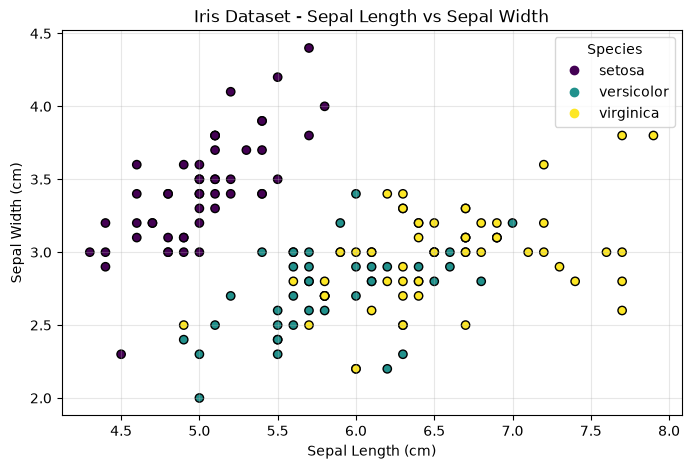

In [2]:
# Visualize the Iris dataset
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    iris.data[:, 0],  # Sepal length
    iris.data[:, 1],  # Sepal width
    c=iris.target,
    cmap="viridis",
    edgecolor="black"
)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Iris Dataset - Sepal Length vs Sepal Width")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=iris.target_names,
    title="Species"
)

plt.grid(alpha=0.3)
plt.show()

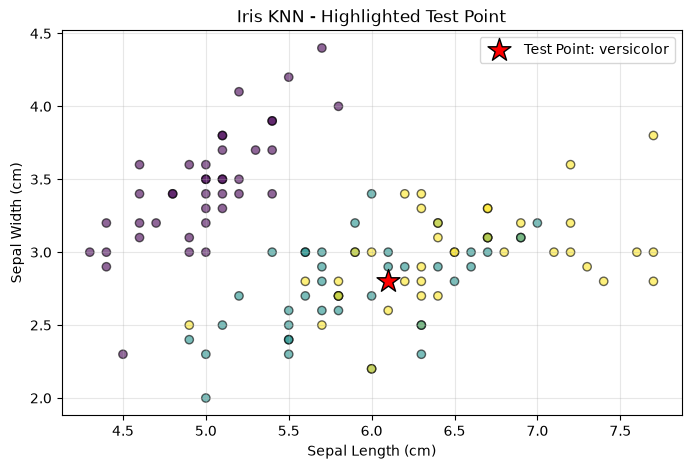

Predicted Species: versicolor


In [3]:
# Visualize Iris dataset with a highlighted test point
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Plot training data
plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.6,
    edgecolor="black"
)

# Select the first test record
test_point = X_test[0]
predicted_species = iris.target_names[y_pred[0]]

# Highlight the test point
plt.scatter(
    test_point[0],
    test_point[1],
    color="red",
    marker="*",
    s=300,
    edgecolor="black",
    label=f"Test Point: {predicted_species}"
)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Iris KNN - Highlighted Test Point")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Predicted Species:", predicted_species)

## Part 2: KNN on a Real-World Weather Dataset

## Step 1: Data Acquisition

### Objective
The objective of this step is to collect weather data that
we can use for exploratory data analysis and KNN classification.

### Steps
1. Load weather data from weather_data.csv.
2. Clean and preprocess the data.
3. Select features and create target labels.
4. Train the KNN model using an ML Pipeline.
5. Evaluate accuracy and visualize results.

### Data Source
For this workshop, we used a CSV dataset named weather_data.csv from Open-Metro, containing hourly weather information for Berlin, Germany.

The dataset contains 168 records with the following attributes:
- **Time:** Date and time of the weather record.
- **Temperature:** Air temperature in degrees Celsius.
- **Relative Humidity:** Amount of moisture in the air (%).
- **Precipitation:** Amount of rainfall or other precipitation (mm).
- **Wind Speed:** Wind speed measured in km/h.

We loaded the dataset using pandas for data analysis, preprocessing, and KNN classification.

Using a saved CSV allows us to work with consistent data and reproduce the results throughout the workshop.

### Why are we using this dataset?
This dataset contains numerical weather features that we
can analyze and use in a KNN classification model.

Our goal is to classify weather conditions as rainy or
not rainy based on weather measurements.

In [4]:
import pandas as pd

# Load the existing weather dataset from CSV
file_path = "../data/weather_data.csv"

weather_df = pd.read_csv(file_path)

# Convert time column to datetime format
weather_df["time"] = pd.to_datetime(weather_df["time"])

# Display dataset information
print("Dataset Shape:", weather_df.shape)

print("\nColumn Names:")
print(weather_df.columns.tolist())

print("\nFirst 5 Records:")
display(weather_df.head())

# Check the weather class distribution
print("\nWeather Class Distribution:")
print(
    (weather_df["precipitation"] > 0)
    .astype(int)
    .value_counts()
    .sort_index()
)

Dataset Shape: (168, 5)

Column Names:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m']

First 5 Records:


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2026-10-13 00:00:00,7.5,79,0.0,3.3
1,2026-10-13 01:00:00,6.9,81,0.0,2.3
2,2026-10-13 02:00:00,5.8,87,0.0,1.1
3,2026-10-13 03:00:00,5.5,91,0.0,0.5
4,2026-10-13 04:00:00,5.3,89,0.0,2.6



Weather Class Distribution:
precipitation
0    163
1      5
Name: count, dtype: int64


### Data Acquisition — Observations 

**What did we do?**

We use a saved CSV dataset originally collected from the Open-Meteo Weather API for Berlin, Germany.

The dataset contains hourly temperature, relative humidity, precipitation, and wind speed measurements.

We load the CSV using pandas to ensure consistent and reproducible results throughout the workshop.

**Why did we use Pandas?**

Pandas helps us organize data into rows and columns.
It makes it easier to inspect, clean, analyze and prepare
the data for machine learning.

**What does the dataset shape mean?**

The dataset contains 168 rows and 5 columns.

- Each row represents one hourly weather record.
- Each column represents a weather attribute.
- The dataset contains seven days of hourly forecast data.

**How does this help our KNN project?**

We need a structured dataset before training a machine
learning model. This data will allow us to analyze
weather patterns and later classify rainy and
non-rainy conditions.

#### Dataset Reproducibility

We saved the collected weather data as a CSV file named
`weather_data.csv`.

This allows all team members to use the same dataset
without repeatedly requesting updated forecast data.

It also helps make our machine learning results
more reproducible.



## Step 2: Data Inspection and Descriptive Statistics

### Objective
Before using the dataset for machine learning, we need to
understand its structure and check its quality.

We will perform the following tasks:

1. Check the number of rows and columns.
2. Examine the data types of each column.
3. Identify missing values.
4. Check for duplicate records.
5. Generate descriptive statistics.

### Why is this important?

- Missing values can affect machine learning performance.
- Incorrect data types can cause errors during analysis.
- Duplicate records may affect our results.
- Descriptive statistics help us understand the range
  and average values of weather measurements.


In [5]:
# Step 2: Data Inspection and Descriptive Statistics

# 1. Display dataset structure
print("Dataset Information:")
weather_df.info()

# 2. Check column data types
print("\nData Types:")
display(weather_df.dtypes.to_frame(name="Data Type"))

# 3. Check missing values
print("\nMissing Values:")

missing_values = pd.DataFrame({
    "Missing Count": weather_df.isnull().sum(),
    "Missing Percentage": (
        weather_df.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

# 4. Check duplicate records
print("\nDuplicate Records:")
print(weather_df.duplicated().sum())

# Descriptive statistics for numerical features
print("\nDescriptive Statistics:")

numerical_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m"
]

statistics = weather_df[numerical_features].describe()

# Round values for better readability
display(statistics.round(2))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  168 non-null    datetime64[us]
 1   temperature_2m        168 non-null    float64       
 2   relative_humidity_2m  168 non-null    int64         
 3   precipitation         168 non-null    float64       
 4   wind_speed_10m        168 non-null    float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 6.7 KB

Data Types:


,Data Type
time,datetime64[us]
temperature_2m,float64
relative_humidity_2m,int64
precipitation,float64
wind_speed_10m,float64



Missing Values:


,Missing Count,Missing Percentage
time,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
precipitation,0,0.0
wind_speed_10m,0,0.0



Duplicate Records:
0

Descriptive Statistics:


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
count,168.00,168.00,168.00,168.00
mean,10.72,77.54,0.02,7.02
std,3.17,13.12,0.25,3.58
min,2.60,45.00,0.00,0.50
25%,8.60,67.75,0.00,4.60
50%,11.00,79.00,0.00,6.10
75%,12.90,89.00,0.00,8.90
max,18.90,100.00,3.20,17.90


### Data Quality Findings

After inspecting the dataset, we found:

- The dataset contains 168 rows and 5 columns.
- All columns have appropriate data types.
- There are no missing values in any column.
- There are no duplicate records.

### Decision

Since there are no missing values or duplicate records, we do not need to perform missing-value imputation or duplicate removal at this stage.


### Understanding Descriptive Statistics

Descriptive statistics help us understand the numerical
characteristics of the dataset.

- **Count:** Number of available records.
- **Mean:** Average value of a weather feature.
- **Standard Deviation:** How much the values vary.
- **Minimum:** Smallest recorded value.
- **25%:** First quartile (Q1).
- **50%:** Median value.
- **75%:** Third quartile (Q3).
- **Maximum:** Largest recorded value.

These statistics help us identify patterns and unusual values
before building the KNN model.


## Step 3: Data Distribution Visualization

### Objective

The goal of this step is to understand how different weather
features are distributed across the dataset.

We will create histograms for:

1. Temperature
2. Relative Humidity
3. Precipitation
4. Wind Speed

### What is a Histogram?

A histogram shows how frequently different numerical values
occur in a dataset.

For example, a temperature histogram helps us identify
which temperature ranges occur most frequently.

### Why is this important for KNN?

KNN calculates distances between data points.

Understanding feature distributions helps us identify
unusual values, differences in feature scales, and
potential data imbalance.


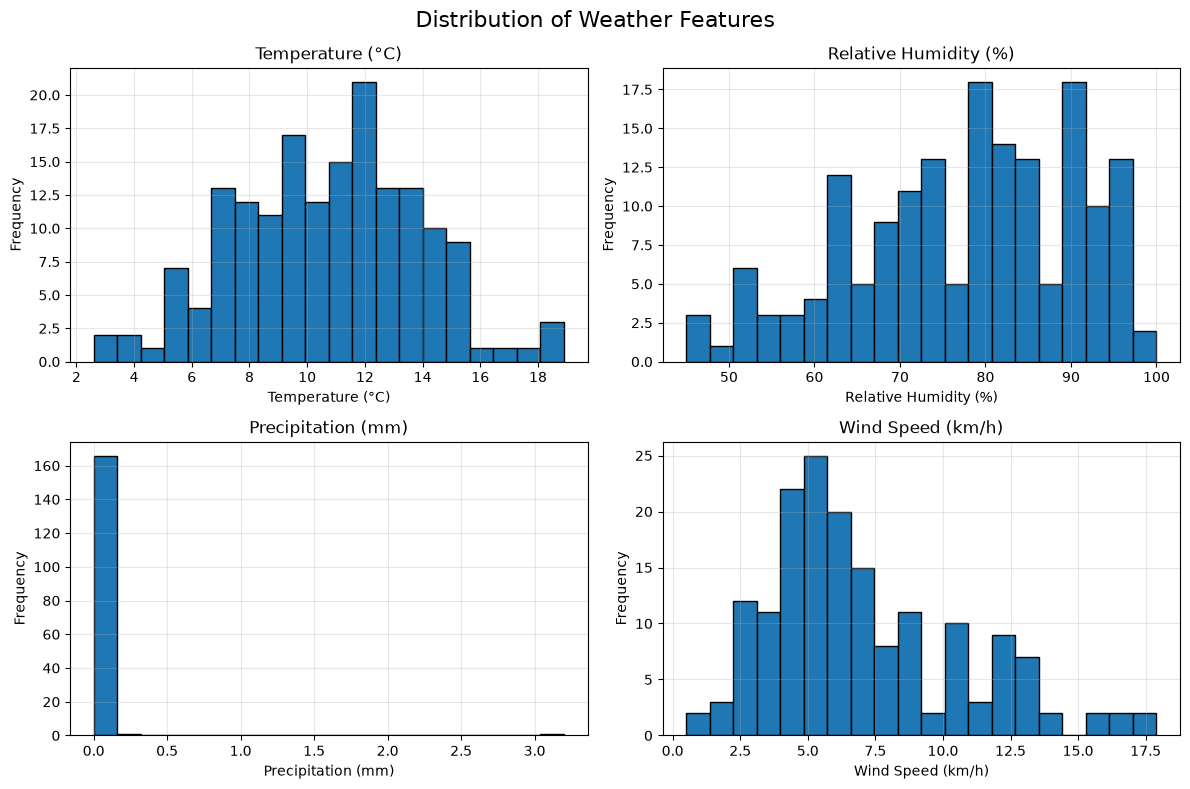

In [6]:
import matplotlib.pyplot as plt

# Weather features and their labels
features = {
    "temperature_2m": "Temperature (°C)",
    "relative_humidity_2m": "Relative Humidity (%)",
    "precipitation": "Precipitation (mm)",
    "wind_speed_10m": "Wind Speed (km/h)"
}

# Create histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, label) in zip(
    axes.flatten(),
    features.items()
):
    ax.hist(
        weather_df[column].dropna(),
        bins=20,
        edgecolor="black"
    )

    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Distribution of Weather Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### Histogram Analysis — Observations

After visualizing the weather dataset, we observed the following:

- **Temperature:** Most temperature values are between 7°C and 14°C, with the highest frequency around 10–11°C.
- **Humidity:** Many humidity values are concentrated between 85% and 94%, indicating frequent high-humidity conditions.
- **Precipitation:** Most records have zero precipitation, while only a small number of hours show rainfall or other precipitation.
- **Wind Speed:** Wind speed values are spread across approximately 2–18 km/h.

### Key Findings

The precipitation histogram shows that the dataset contains mostly zero-precipitation records. This suggests a possible class imbalance between rainy and non-rainy conditions.

Since we are using KNN for classification, class imbalance may affect model performance.


## Step 4: Boxplots and Outlier Analysis

### Objective

The purpose of this step is to identify unusual values
in our weather dataset using boxplots.

### What is a Boxplot?

A boxplot shows the distribution of numerical data using:

- **Median:** The middle value of the dataset.
- **Q1:** The 25th percentile.
- **Q3:** The 75th percentile.
- **Whiskers:** The range of values within the boxplot limits.
- **Outliers:** Values outside the whiskers that may be unusual.

### Why is this important for KNN?

KNN uses distance calculations to identify nearby data points.

Unusual values and different feature scales can affect
these calculations.

However, unusual weather values are not always errors.
They may represent real weather conditions.


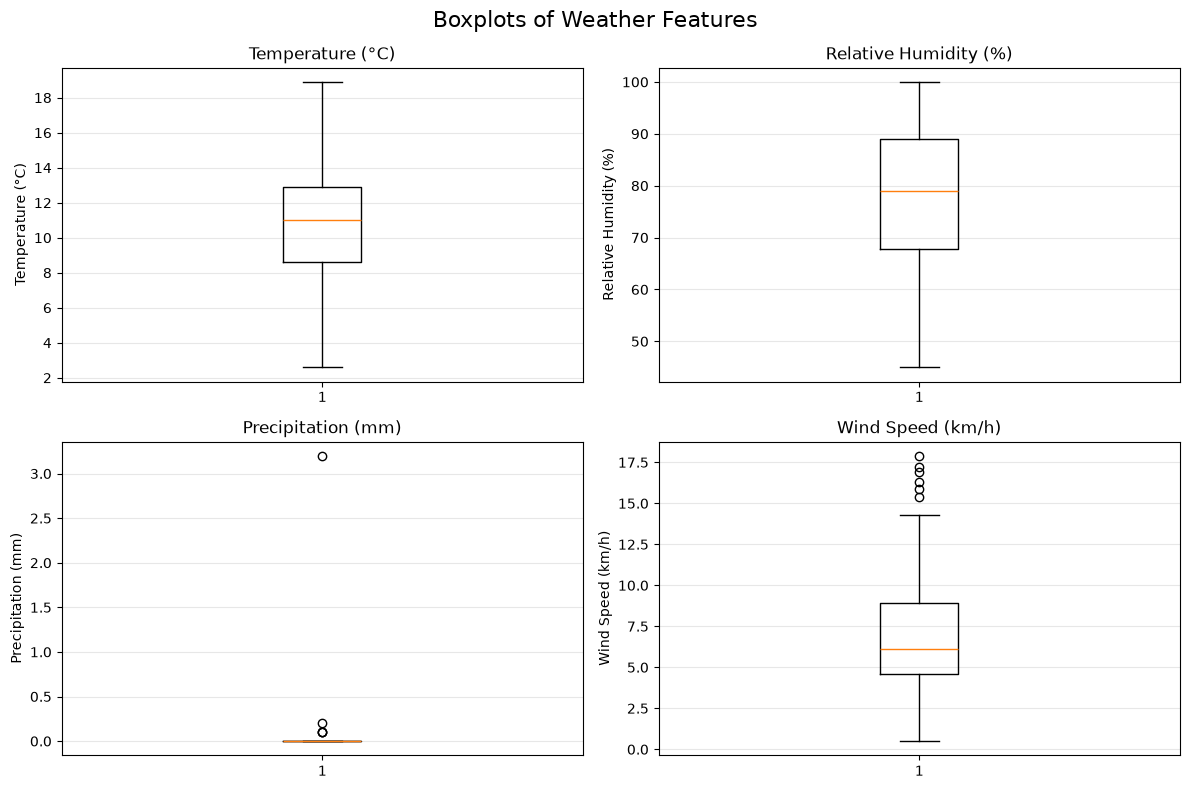

In [7]:
import matplotlib.pyplot as plt

features = {
    "temperature_2m": "Temperature (°C)",
    "relative_humidity_2m": "Relative Humidity (%)",
    "precipitation": "Precipitation (mm)",
    "wind_speed_10m": "Wind Speed (km/h)"
}

# Create boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, label) in zip(
    axes.flatten(),
    features.items()
):
    ax.boxplot(
        weather_df[column].dropna()
    )

    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Boxplots of Weather Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### Boxplot Analysis — Observations

We created boxplots to identify potential outliers in the weather dataset.

- **Temperature:** The values are distributed within the expected range, with no visible outliers.
- **Humidity:** No significant outliers were detected.
- **Precipitation:** Several positive precipitation values appear as outliers because most records contain zero precipitation.
- **Wind Speed:** The values show some variation, but no visible outliers were detected.

### Decision on Outlier Handling

We decided not to remove the precipitation outliers because they represent actual forecast weather conditions.

Removing these values could negatively affect our KNN classification model, as we are trying to distinguish between rainy and non-rainy conditions.

## Step 5: Target Class Distribution

### Objective

The purpose of this step is to understand how many weather
records represent rainy and non-rainy conditions.

### Target Variable

We create a new column called `rainy` using precipitation:

- 0 = Not Rainy (precipitation is zero)
- 1 = Rainy (precipitation is greater than zero)

### Why is this important?

KNN is a classification algorithm that learns from
labeled data.

By examining the number of rainy and non-rainy records,
we can determine whether our target classes are balanced.

An imbalanced dataset may cause the model to predict
the majority class more frequently.


,Class,Count,Percentage (%)
0,Not Rainy,163,97.02
1,Rainy,5,2.98


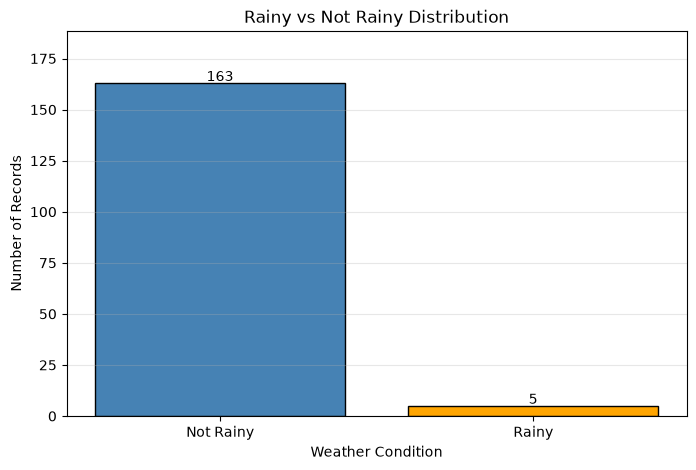

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a copy of the original weather dataset
clean_df = weather_df.copy()

# Create binary target variable
clean_df["rainy"] = (
    clean_df["precipitation"] > 0
).astype(int)

# Count records in each class
class_counts = clean_df["rainy"].value_counts().reindex(
    [0, 1],
    fill_value=0
)

# Calculate percentages
class_percentages = (
    class_counts / len(clean_df) * 100
).round(2)

# Display class distribution
class_distribution = pd.DataFrame({
    "Class": ["Not Rainy", "Rainy"],
    "Count": class_counts.values,
    "Percentage (%)": class_percentages.values
})

display(class_distribution)

# Visualize class distribution
plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_distribution["Class"],
    class_distribution["Count"],
    color=["steelblue", "orange"],
    edgecolor="black"
)

# Display counts above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{int(height)}",
        ha="center"
    )

plt.title("Rainy vs Not Rainy Distribution")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Records")
plt.ylim(0, max(class_counts) * 1.15 + 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Step 5: Class Distribution — Observations

We created a target variable called `rainy` based on precipitation values.

- **Not Rainy (0):** 163 records (97.02%)
- **Rainy (1):** 5 records (2.98%)
- **Total:** 168 records

### Key Finding

The dataset is highly imbalanced because most records belong to the non-rainy class.

This may affect the KNN model's ability to correctly identify rainy conditions. Therefore, we use precision, recall, F1-score, and a confusion matrix in addition to accuracy when evaluating the model.

## Data Cleaning and Feature Engineering

This section validates the weather data, removes duplicate records, creates numerical time-based features, selects input features and the target, and splits the dataset into training and testing sets. Missing-value imputation and feature scaling are handled by the KNN pipeline.

In [9]:
# Data Cleaning and Feature Engineering

import numpy as np
from sklearn.model_selection import train_test_split

# 1. Convert time to datetime
clean_df["time"] = pd.to_datetime(
    clean_df["time"], errors="coerce"
)

# 2. Remove invalid timestamps and duplicates
clean_df = clean_df.dropna(subset=["time"])
clean_df = clean_df.drop_duplicates()

# 3. Create numerical time-based features
clean_df["hour"] = clean_df["time"].dt.hour

clean_df["hour_sin"] = np.sin(
    2 * np.pi * clean_df["hour"] / 24
)
clean_df["hour_cos"] = np.cos(
    2 * np.pi * clean_df["hour"] / 24
)

# 4. Select features (X)
# Exclude precipitation because it defines the target
X = clean_df[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "hour_sin",
        "hour_cos"
    ]
]

# 5. Select target (y)
y = clean_df["rainy"]

# 6. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 7. Display validation results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (134, 5)
Testing features: (34, 5)
Training target: (134,)
Testing target: (34,)


### Summary of Data Cleaning and Feature Engineering

The weather dataset was prepared for KNN classification by converting the timestamp to datetime format, removing invalid timestamps and duplicate records, and creating numerical time-based features using sine and cosine transformations.

The input features (`X`) were selected using temperature, relative humidity, wind speed, and the engineered time features. The target variable (`y`) was `rainy`, representing whether precipitation occurred. Precipitation was excluded from the input features to avoid target leakage.

The dataset was split into training and testing sets using an 80:20 ratio. Missing-value imputation and feature scaling are handled by the existing KNN pipeline to prepare the data for model training.
**Categorical Encoding Decision**

The selected input features are numerical, so one-hot encoding or label encoding is not required. The timestamp was converted to datetime format, and the hour was transformed into sine and cosine features to represent its cyclical nature.

## EDA Summary and Conclusion

### Summary

In this workshop, we collected and explored weather data using the Open-Meteo API.

The dataset contains 168 hourly weather records with information about temperature, humidity, precipitation and wind speed.

We performed data inspection, missing-value analysis, descriptive statistics and data visualizations.

### Key Findings

- The dataset contains 168 hourly weather records with no missing values or duplicates.
- The average temperature is approximately 10.72°C.
- The average humidity is approximately 77.54%.
- Most records have zero precipitation.
- Positive precipitation values were retained because they represent meaningful weather conditions.
- The dataset contains 163 non-rainy records (97.02%) and 5 rainy records (2.98%).

The dataset is highly imbalanced, which may affect KNN classification performance.

### Dataset Limitations

The dataset covers only seven days of hourly weather forecasts from Berlin, Germany. Therefore, it may not represent longer-term or seasonal weather patterns.

The dataset also contains relatively few rainy records, which may make it difficult for the model to identify rainy conditions accurately.

### Conclusion

Our exploratory data analysis helped us understand the structure, quality, and distribution of the weather dataset.

The analysis helped us identify the preprocessing and feature engineering steps needed for KNN classification.

Since the dataset contains fewer rainy records, class imbalance should be considered when evaluating model performance.


## Step 6: KNN Model Training Using ML Pipeline

We implement a KNN classifier using the scikit-learn Pipeline with three components:

1. **SimpleImputer:** Handles missing values using the median.
2. **StandardScaler:** Standardizes numerical features.
3. **KNeighborsClassifier:** Trains the initial model using K = 3 and Euclidean distance.

This initial model will be used as a baseline for hyperparameter comparison.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

# Train the KNN model
knn_pipeline.fit(X_train, y_train)

# Predict weather conditions
y_pred = knn_pipeline.predict(X_test)

print("KNN model trained successfully!")
print("Predictions:", y_pred)

KNN model trained successfully!
Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## Step 7: KNN Model Evaluation (Euclidean KNN model)

We evaluate the KNN classifier using accuracy, precision,
recall, F1-score, and a confusion matrix.

These metrics help us understand how well the model classifies
rainy and non-rainy weather.

Since our dataset is imbalanced, we consider precision,
recall, and F1-score in addition to accuracy.

KNN Model Evaluation
----------------------------
Accuracy:  0.9706
Precision: 0.5000
Recall:    1.0000
F1 Score:  0.6667

Classification Report:
              precision    recall  f1-score   support

   Not Rainy       1.00      0.97      0.98        33
       Rainy       0.50      1.00      0.67         1

    accuracy                           0.97        34
   macro avg       0.75      0.98      0.83        34
weighted avg       0.99      0.97      0.98        34



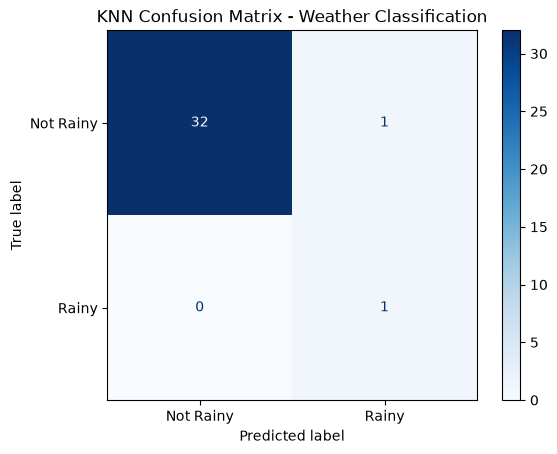

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("KNN Model Evaluation")
print("----------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not Rainy", "Rainy"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Not Rainy", "Rainy"],
    cmap="Blues"
)

plt.title("KNN Confusion Matrix - Weather Classification")
plt.show()

### Step 7: Model Evaluation — Observations

We evaluated the initial KNN model using **K = 3 and Euclidean distance** on 34 test records.

**Results:**
- Accuracy: 97.06%
- Precision: 50%
- Recall: 100%
- F1-score: 66.67%

### Key Findings

- The model correctly classified 33 out of 34 weather records.
- It correctly identified 32 non-rainy records and 1 rainy record.
- It incorrectly predicted rain for 1 non-rainy record.
- The model identified the only rainy record in the test dataset, resulting in 100% recall.
- However, its precision was only 50%, indicating that not all predicted rainy conditions were correct.

### Conclusion

The initial KNN model achieved high overall accuracy. However, the test dataset contained only one rainy record, making it difficult to assess how reliably the model can identify rain.

We also compared different K values and distance metrics using cross-validation to investigate model performance.

## Step 8: KNN Hyperparameter Comparison

We experiment with different K values (3, 5, 7, and 9)
and two distance metrics: Euclidean and Manhattan.

We use stratified cross-validation on the training data
to compare model performance using F1-score.

The goal is to identify a suitable KNN configuration
for classifying rainy and non-rainy weather.

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import pandas as pd

# Define K values and distance metrics
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9],
    "knn__metric": ["euclidean", "manhattan"]
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search for the best KNN configuration
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Train using the training dataset only
grid_search.fit(X_train, y_train)

# Display the best configuration
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1:", round(grid_search.best_score_, 4))

# Compare all combinations
results_df = pd.DataFrame(grid_search.cv_results_)

comparison = results_df[
    [
        "param_knn__n_neighbors",
        "param_knn__metric",
        "mean_test_score"
    ]
].copy()

comparison.columns = [
    "K Value",
    "Distance Metric",
    "Mean CV F1 Score"
]

display(comparison.sort_values(
    by="Mean CV F1 Score",
    ascending=False
))

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 3}
Best Cross-Validation F1: 0.0


,K Value,Distance Metric,Mean CV F1 Score
0,3,euclidean,0.0
1,5,euclidean,0.0
2,7,euclidean,0.0
3,9,euclidean,0.0
4,3,manhattan,0.0
5,5,manhattan,0.0
6,7,manhattan,0.0
7,9,manhattan,0.0


### Step 8: Hyperparameter Tuning — Observations

We compared K values of 3, 5, 7, and 9 using Euclidean and Manhattan distance metrics.

**GridSearchCV Results:**
- Reported K Value: 3
- Reported Distance Metric: Euclidean
- Cross-Validation F1-score: 0.0000

### Observation

All eight configurations produced a cross-validation F1-score of 0.0.

GridSearchCV reported K = 3 with Euclidean distance, but this was a tied result rather than a clearly better configuration.

The dataset contains very few rainy records, making it difficult for the model to identify rainy conditions consistently during cross-validation.

### Conclusion

Hyperparameter tuning allowed us to compare different K values and distance metrics.

However, the results did not identify a clearly superior model. We also evaluated K = 3 with Manhattan distance as a separate experiment.

## Step 9: Modular ML Pipeline Architecture

We organize the KNN implementation into reusable functions
following the Machine Learning Pipeline Pattern.

The workflow includes:
1. Data loading
2. Data preprocessing and feature engineering
3. KNN model training
4. Model evaluation

This approach improves code readability, reusability,
and maintainability.

In [13]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# Step 1: Data Loading
def load_data(file_path="../data/weather_data.csv"):
    df = pd.read_csv(file_path)
    return df


# Step 2: Data Preprocessing
def preprocess_data(df):

    df = df.copy()

    df["time"] = pd.to_datetime(
        df["time"], errors="coerce"
    )

    df = df.dropna(subset=["time", "precipitation"])
    df = df.drop_duplicates()

    # Create target
    df["rainy"] = (df["precipitation"] > 0).astype(int)

    # Time-based feature engineering
    df["hour"] = df["time"].dt.hour
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

    # Select features
    features = [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "hour_sin",
        "hour_cos"
    ]

    X = df[features]
    y = df["rainy"]

    return train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )


# Step 3: KNN Model Training
def train_model(X_train, y_train, k=3, metric="manhattan"):

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=k,
            metric=metric
        ))
    ])

    model.fit(X_train, y_train)

    return model


# Step 4: Model Evaluation
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print(f"Accuracy: {accuracy:.4f}")

    return predictions


# Execute the modular workflow
modular_df = load_data()

X_train_mod, X_test_mod, y_train_mod, y_test_mod = (
    preprocess_data(modular_df)
)

modular_model = train_model(
    X_train_mod,
    y_train_mod,
    k=3,
    metric="manhattan"
)

modular_predictions = evaluate_model(
    modular_model,
    X_test_mod,
    y_test_mod
)

print("Modular KNN Pipeline executed successfully!")

Accuracy: 0.9706
Modular KNN Pipeline executed successfully!


### Step 9: Modular ML Pipeline — Observations

We implemented the KNN model using reusable functions for data loading, preprocessing, training, and evaluation.

**Results:**
- K Value: 3
- Distance Metric: Manhattan
- Model Accuracy: 97.06%

### Conclusion

The modular pipeline executed successfully using K = 3 with Manhattan distance.

This model was tested as a separate experiment. GridSearchCV did not identify a clearly superior configuration because all tested combinations produced the same cross-validation F1-score of 0.0.

The modular approach improves code readability, reusability, and maintainability.

### Manhattan KNN Model — Additional Evaluation

We also trained a KNN model using K = 3 with Manhattan distance to compare its performance with the initial Euclidean model.

GridSearchCV compared different K values and distance metrics, but all configurations produced a cross-validation F1-score of 0.0. Therefore, no clearly superior configuration was identified.

We retained the Manhattan model as an additional experiment.

The predictions from this model are used for further performance analysis.

In [14]:
# Final model selected after hyperparameter tuning
final_model = modular_model

# Generate predictions using the final model
final_predictions = final_model.predict(X_test_mod)

print("Manhattan KNN Model - Additional Evaluation")
print("K Value: 3")
print("Distance Metric: Manhattan")
print("Total Predictions:", len(final_predictions))
print("Predictions:", final_predictions)




Manhattan KNN Model - Additional Evaluation
K Value: 3
Distance Metric: Manhattan
Total Predictions: 34
Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### Step 10: Manhattan KNN Model Evaluation (K = 3)

Step 9 reported the accuracy of the Manhattan KNN model.

Because the dataset is highly imbalanced, with only 5 rainy records (2.98%) out of 168 records, accuracy alone may not provide a complete picture of model performance.

In this step, we evaluate the Manhattan KNN model using a confusion matrix, precision, recall, and F1-score.

These metrics help us understand how well the model identifies rainy and non-rainy conditions.

Final KNN Model (K = 3, Manhattan) - Evaluation
-----------------------------------------------
Accuracy:  0.9706
Precision: 0.5000
Recall:    1.0000
F1 Score:  0.6667

Classification Report:
              precision    recall  f1-score   support

   Not Rainy       1.00      0.97      0.98        33
       Rainy       0.50      1.00      0.67         1

    accuracy                           0.97        34
   macro avg       0.75      0.98      0.83        34
weighted avg       0.99      0.97      0.98        34



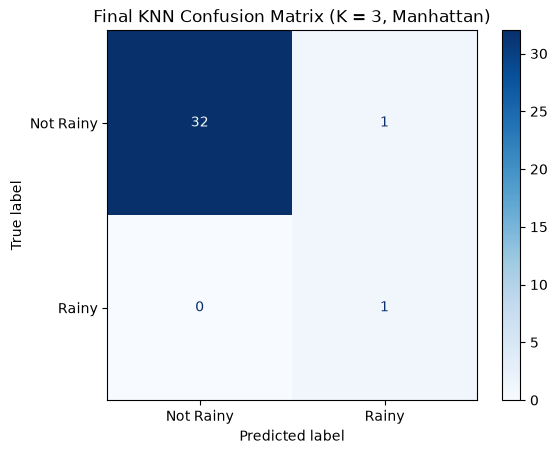

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Evaluate the final model on the test set
print("Final KNN Model (K = 3, Manhattan) - Evaluation")
print("-----------------------------------------------")
print(f"Accuracy:  {accuracy_score(y_test_mod, final_predictions):.4f}")
print(f"Precision: {precision_score(y_test_mod, final_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_mod, final_predictions, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_mod, final_predictions, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_mod,
    final_predictions,
    labels=[0, 1],
    target_names=["Not Rainy", "Rainy"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_mod,
    final_predictions,
    labels=[0, 1],
    display_labels=["Not Rainy", "Rainy"],
    cmap="Blues"
)
plt.title("Final KNN Confusion Matrix (K = 3, Manhattan)")
plt.show()

### Step 11: Precision, Recall and F1-score Calculated Manually

The scikit-learn functions hide the calculation. Here we compute the metrics ourselves
from the four confusion-matrix counts, where "Rainy" is the positive class:

| Count | Meaning |
|---|---|
| **TP** (true positive) | Rainy hours correctly predicted as rainy |
| **FP** (false positive) | Not-rainy hours wrongly predicted as rainy (false alarms) |
| **FN** (false negative) | Rainy hours the model missed |
| **TN** (true negative) | Not-rainy hours correctly predicted as not rainy |

**Formulas**

- Precision = TP / (TP + FP): of all hours predicted rainy, how many really were rainy?
- Recall = TP / (TP + FN): of all hours that really were rainy, how many did we catch?
- F1 = 2 x Precision x Recall / (Precision + Recall): the harmonic mean of the two.

In [16]:
# Manual calculation from the confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test_mod, final_predictions, labels=[0, 1]
).ravel()

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

# Manual recall (guard against division by zero)
manual_recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

# Manual precision
manual_precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0

# Manual F1-score
if (manual_precision + manual_recall) > 0:
    manual_f1 = 2 * manual_precision * manual_recall / (manual_precision + manual_recall)
else:
    manual_f1 = 0.0

print(f"\nManual Recall:    {manual_recall:.4f}   (TP / (TP + FN) = {tp} / {tp + fn})")
print(f"Manual Precision: {manual_precision:.4f}   (TP / (TP + FP) = {tp} / {tp + fp})")
print(f"Manual F1 Score:  {manual_f1:.4f}")

# Check our manual results against scikit-learn
print("\nMatches scikit-learn?")
print("Recall:   ", np.isclose(manual_recall, recall_score(y_test_mod, final_predictions, zero_division=0)))
print("Precision:", np.isclose(manual_precision, precision_score(y_test_mod, final_predictions, zero_division=0)))
print("F1:       ", np.isclose(manual_f1, f1_score(y_test_mod, final_predictions, zero_division=0)))

TN = 32, FP = 1, FN = 0, TP = 1

Manual Recall:    1.0000   (TP / (TP + FN) = 1 / 1)
Manual Precision: 0.5000   (TP / (TP + FP) = 1 / 2)
Manual F1 Score:  0.6667

Matches scikit-learn?
Recall:    True
Precision: True
F1:        True


### Step 12: Precision vs Recall in Real-World Cases

Precision and recall pull in opposite directions. Which one matters more depends on
which mistake is more costly.

**Recall matters more when a missed positive is costly (false negatives are dangerous)**

- **Medical screening (for example cancer):** missing a sick patient is far worse than
  sending a healthy patient for another test.
- **Fraud detection:** letting a fraudulent transaction through costs more than
  briefly flagging a legitimate one for review.
- **Safety and disaster warnings (flood, fire, severe storm):** a missed warning can
  cost lives, while a false alarm costs only some inconvenience.

**Precision matters more when a false alarm is costly (false positives are expensive)**

- **Spam filtering:** wrongly sending an important email to the spam folder is worse
  than letting an occasional spam message through.
- **Recommending content or sending marketing offers:** wrong guesses waste money
  and make people ignore future messages.
- **Automatic account suspension or legal flagging:** punishing an innocent
  person is a serious error.

**When both matter,** use the **F1-score**, which is high only when precision and
recall are both reasonably high.

**Our rainy-weather model**

- If the goal is to protect something that rain would damage (an outdoor event,
  drying crops, an open construction site), a missed rain hour (FN) is costly, so we would favour **recall**.
- If the goal is a casual "bring an umbrella" alert, frequent false alarms
  (FP) annoy people and they stop trusting the alert, so **precision** matters more.
- Our Euclidean baseline achieved 100% recall and 50% precision. It correctly identified the only rainy record in the test set but incorrectly predicted rain for one non-rainy record. Since the test set contains only one rainy record, these results should be interpreted carefully. 

The next step shows how changing the decision threshold affects precision and recall.


### Step 13: Effect of the Decision Threshold on Precision and Recall

A classifier does not have to use its default rule. KNN can output the **probability**
of the rainy class (the fraction of the K neighbours that are rainy), and we choose the
**threshold** above which we predict "rainy":

- `predict()` is equivalent to a threshold of **0.5** (majority vote).
- **Lower threshold:** more hours are predicted rainy, so recall tends to go **up** and precision tends to go **down**.
- **Higher threshold:** fewer hours are predicted rainy, so precision tends to go **up** and recall tends to go **down**.

**Note on KNN:** with K = 3 the probability can only be 0, 1/3, 2/3 or 1, so the
results change in steps rather than smoothly. A larger K gives finer probabilities.

Distinct probability values: [0.    0.333 0.667]
Threshold 0.5 matches predict(): True


,Threshold,Predicted Rainy,Precision,Recall,F1 Score
0,0.1,3,0.333,1.0,0.500
1,0.2,3,0.333,1.0,0.500
2,0.3,3,0.333,1.0,0.500
3,0.4,2,0.500,1.0,0.667
4,0.5,2,0.500,1.0,0.667
5,0.6,2,0.500,1.0,0.667
6,0.7,0,0.000,0.0,0.000
7,0.8,0,0.000,0.0,0.000
8,0.9,0,0.000,0.0,0.000


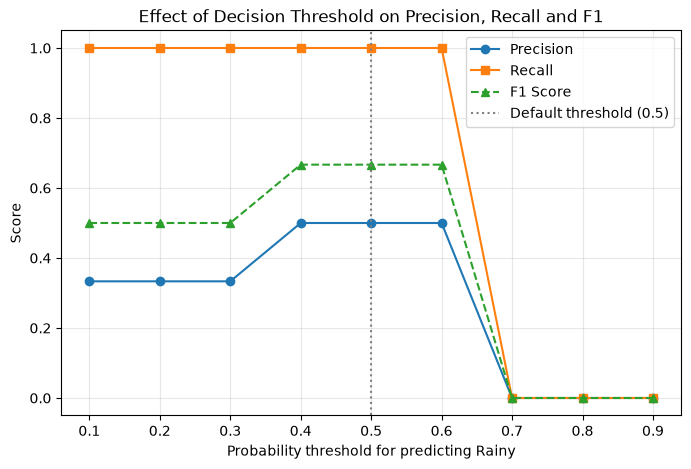

In [17]:
# Probability of the "Rainy" class from the final model
proba_rainy = final_model.predict_proba(X_test_mod)[:, 1]

print("Distinct probability values:", np.unique(np.round(proba_rainy, 3)))

# A threshold of 0.5 should reproduce the default predict() output
default_equivalent = (proba_rainy >= 0.5).astype(int)
print("Threshold 0.5 matches predict():", np.array_equal(default_equivalent, final_predictions))

# Try thresholds from 0.1 to 0.9
thresholds = np.round(np.arange(0.1, 1.0, 0.1), 2)

rows = []
for th in thresholds:
    pred_th = (proba_rainy >= th).astype(int)
    rows.append({
        "Threshold": th,
        "Predicted Rainy": int(pred_th.sum()),
        "Precision": precision_score(y_test_mod, pred_th, zero_division=0),
        "Recall": recall_score(y_test_mod, pred_th, zero_division=0),
        "F1 Score": f1_score(y_test_mod, pred_th, zero_division=0)
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df.round(3))

# Plot precision, recall and F1 against the threshold
plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="s", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1 Score"], marker="^", linestyle="--", label="F1 Score")
plt.axvline(0.5, color="gray", linestyle=":", label="Default threshold (0.5)")
plt.title("Effect of Decision Threshold on Precision, Recall and F1")
plt.xlabel("Probability threshold for predicting Rainy")
plt.ylabel("Score")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Threshold Analysis: What to Look For

Use the table and plot above to answer:

1. **What happens to recall as the threshold is lowered?** More hours are labelled rainy, so
   fewer real rainy hours are missed (FN falls) and recall rises or stays the same.
2. **What happens to precision as the threshold is lowered?** More non-rainy hours are
   wrongly labelled rainy (FP rises), so precision usually falls.
3. **Which threshold gives the best F1-score?** This is the best balance of the two.
4. **Which threshold would you choose, and why?** It depends on the use case from Step 12:
   a lower threshold if missing rain is costly, a higher threshold if false alarms are costly.

**Caution:** The test set contains only 34 records, including 1 rainy record. Therefore, even one incorrect prediction can significantly affect precision and recall.

These results demonstrate the trade-off between precision and recall, but they are not sufficient for selecting a final decision threshold. Threshold selection should be performed using validation data or cross-validation on the training set rather than the test set.

## Workshop Reflection

### Question 1: How did KNN perform on your dataset?

We applied KNN classification to our weather dataset to predict whether it would rain.

We tested K = 3 using Euclidean and Manhattan distance metrics. Both models achieved:

- **Accuracy:** 97.06%
- **Precision:** 50%
- **Recall:** 100%
- **F1-score:** 66.67%

Although accuracy was high, our dataset contained only 5 rainy records out of 168 observations. The test set had only one rainy record.

Therefore, we cannot conclude that the model will perform equally well on new weather data. A larger dataset with more rainy examples would help us evaluate its performance more reliably.

### Question 2: What preprocessing steps were necessary, and why?

Before training the KNN model, we performed the following preprocessing steps:

- **Target creation:** Created a `rainy` column based on precipitation values (0 = Not Rainy, 1 = Rainy).
- **Feature selection:** Selected temperature, humidity, wind speed, and time-based features for prediction.
- **Time transformation:** Converted the hour into sine and cosine features to represent the repeating 24-hour cycle.
- **Missing value handling:** Used `SimpleImputer` with the median strategy to handle any missing numerical values.
- **Feature scaling:** Applied `StandardScaler` because KNN calculates distances between data points, and features with larger numerical values could otherwise dominate the results.
- **Train-test split:** Divided the dataset into training and testing sets to evaluate the model on unseen records.

These preprocessing steps helped prepare the weather data for KNN classification.

### Question 3: What are the strengths and weaknesses of KNN?

**Strengths:**
- KNN is simple to understand and implement.
- It can be used for both classification and regression.
- It does not require a complex training process.
- It makes predictions based on similarities between data points.

**Weaknesses:**
- KNN can be slow when working with large datasets because it calculates distances to training records.
- Its performance depends on the choice of K and the distance metric.
- Feature scaling is important because KNN is distance-based.
- It can struggle with imbalanced datasets.

**Our Observation:**

KNN achieved high accuracy on our weather dataset, but we had very few rainy records. This made it difficult to reliably evaluate how well the model identifies rainy conditions.

Therefore, KNN is useful for learning classification, but we would need more weather data to assess its reliability for real-world rain prediction.

### Question 4: When would KNN not be a good choice?

KNN may not be suitable in the following situations:

- **Large datasets:** KNN can take more time to make predictions because it calculates distances between data points.
- **High-dimensional datasets:** When there are too many features, distances between data points become less meaningful.
- **Imbalanced datasets:** KNN may favor the majority class and struggle to identify less common classes.
- **Real-time applications:** KNN predictions can be slower when the training dataset is very large.

**Our Observation:**

Our weather dataset contains only 5 rainy records out of 168 observations. Because the dataset is highly imbalanced, KNN may not reliably identify rainy conditions.

For more reliable weather prediction, we would need more historical weather data, especially examples of rainy conditions, and compare KNN with other classification models.

### Question 5: How could MLOps practices improve this project?

MLOps helps us organize, automate, and maintain machine learning projects.

We could improve our KNN weather prediction project using the following practices:

- **Version Control:** Use GitHub to track code changes and collaborate with team members.
- **Reproducibility:** Use a fixed CSV dataset and consistent preprocessing steps so the results can be reproduced.
- **Modular Code:** Separate data loading, preprocessing, model training, and evaluation into reusable functions.
- **Model Tracking:** Record model parameters and evaluation metrics to compare different experiments.
- **Automation:** Automatically run data preprocessing, model training, and testing when new data becomes available.
- **Model Monitoring:** Monitor prediction

## Peer Programming and Team Comparison

### 1. Project Comparison

We compared our KNN weather prediction project (Team 5) with Team 2's Heart Disease prediction project.

Our team used 168 weather records to predict whether it would rain. Team 2 used 303 heart disease records to predict whether a patient had heart disease.

### 2. Model Performance

| Metric | Our Team (Weather) | Team 2 (Heart Disease) |
|---|---|---|
| Accuracy | 97.06% | 88.52% |
| Precision | 50.00% | 86.21% |
| Recall | 100.00% | 89.29% |
| F1-score | 66.67% | 87.72% |

Our model achieved higher accuracy, while Team 2 achieved better precision and F1-score.

However, our dataset had only 5 rainy records, so our high accuracy does not necessarily mean our model is better. The two teams also worked on different prediction problems.

### 3. Differences in Implementation

- **Our Team:** Used a CSV dataset, numerical feature scaling, time-based feature engineering, and reusable Python functions.
- **Team 2:** Used the UCI Heart Disease dataset, handled numerical and categorical missing values, applied categorical encoding, and implemented reusable Python classes. They also integrated Neon PostgreSQL.

### 4. Lessons Learned

By comparing both notebooks, we learned that:

- Class imbalance can strongly affect model evaluation.
- Accuracy alone is not enough to judge model performance.
- Different datasets require different preprocessing techniques.
- Both reusable functions and object-oriented classes can support modular ML pipelines.
- Hyperparameter tuning does not always improve model performance.

### 5. Reflection

The comparison helped us understand why precision, recall, and F1-score are important.

Our weather model requires more rainy examples for reliable evaluation. Team 2's project also demonstrated how object-oriented programming and database integration can be used to organize machine learning projects.

This comparison gave us ideas for improving the structure and evaluation of our own project.